<a href="https://colab.research.google.com/github/JulianNguyen05/xiangqi-sorting-jetmax/blob/main/training/image_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TIỀN XỬ LÝ ẢNH — MINH HOẠ TỪNG BƯỚC TRÊN ẢNH BÀN CỜ THẬT

**Đầu vào:** 3 ảnh chụp bàn cờ thật của đề tài trong thư mục `samples/` của repo
**Đầu ra:** hình minh hoạ từng bước xử lý ảnh (dùng cho Chương 4 của báo cáo) — **không huấn luyện, không cần GPU, không cần Drive**

### Vì sao có notebook này?
Các Bước 1–6 tập trung vào dữ liệu, mô hình, luật cờ và đóng gói; phần **xử lý ảnh** nằm trong mã nguồn thư viện (`vision/pieces.py`, `vision/board_detect.py`, `vision/enhance.py`) nhưng chưa được minh hoạ từng bước. Notebook này **gọi đúng các hàm của thư viện** trên ảnh thật để thấy mỗi bước làm gì với ảnh.

| Ảnh | Nội dung |
|---|---|
| `samples/board_empty.jpg` | Bàn cờ trống (tấm nhựa 36 × 26 cm, đường kẻ đỏ) |
| `samples/start_position.jpg` | Thế khai cuộc, 32 quân trên bàn |
| `samples/disorganized_location.png` | Quân để lộn xộn quanh bàn (vùng chờ) |

### Nội dung
1. Chuẩn bị và xem 3 ảnh mẫu
2. Hai nhánh tiền xử lý của hệ thống
3. Nhánh nhận diện quân: letterbox, đổi kênh màu, chuẩn hoá (đầu vào YOLO11n)
4. Nhánh định vị bàn cờ: HSV → phân ngưỡng đỏ → hình thái học → Hough → homography → 90 giao điểm
5. Định vị bàn cờ trên cả 3 ảnh mẫu
6. Xác định màu quân bằng phân ngưỡng HSV
7. Tăng cường chất lượng ảnh (`vision/enhance.py`): đo ảnh, tự bật khử nhiễu / cân bằng trắng / CLAHE
8. Đối chiếu hình trong notebook với hình trong báo cáo

### Tóm tắt một trang (đọc phần này là đủ nếu chỉ quan tâm robot và mô hình học sâu)

Xử lý ảnh trong đề tài là **phần phụ trợ** cho hai thành phần chính: nó chuẩn bị ảnh cho mô hình học sâu và cho robot biết quân nằm ở **ô nào** trên bàn.

| Nhánh | Phục vụ ai | Làm gì | Kết quả trên ảnh mẫu |
|---|---|---|---|
| Chuẩn bị ảnh cho YOLO11n | **Mô hình học sâu** | Letterbox về 640 × 640, BGR → RGB, chia 255 — giống hệt lúc huấn luyện | Ảnh 1280 × 960: tỉ lệ 0.5, đệm 80 px trên/dưới |
| Định vị bàn cờ | **Robot** (đổi pixel → ô cờ → mm) | Lọc màu đỏ của đường kẻ (HSV) → Hough → homography → 90 giao điểm | 16–19 đường khớp, sai lệch 0.5–1.4 mm trên 3 ảnh mẫu |
| Kiểm tra màu quân | Mô hình học sâu (kiểm tra chéo) | Đếm điểm ảnh mực đỏ / đen quanh tâm quân | — |
| Tăng cường ảnh tự động | Robot (ánh sáng phòng thay đổi) | Đo ảnh rồi tự bật khử nhiễu / cân bằng trắng / CLAHE khi cần | Ảnh tốt: giữ nguyên; ảnh nhiễu nặng: từ mất bàn → tìm lại được |

Các mục 3–7 bên dưới là **phần chi tiết để tra cứu** (hình cho Chương 4 của báo cáo); không cần đọc hết để hiểu hệ thống.

---
# 1. Chuẩn bị

In [1]:
import os, sys, subprocess, inspect
import numpy as np, cv2
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    REPO = '/content/xiangqi-sorting-jetmax'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/JulianNguyen05/xiangqi-sorting-jetmax', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=False)
else:
    REPO = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'training' else os.path.abspath('.')
sys.path.insert(0, REPO)

from board.geometry import BoardGeometry, NF, NR
from vision import board_detect as bd
from vision.pieces import letterbox, ink_color

plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'figure.dpi': 80})
RGB = lambda b: cv2.cvtColor(b, cv2.COLOR_BGR2RGB)
SAMPLES = os.path.join(REPO, 'samples')
names = ['board_empty.jpg', 'start_position.jpg', 'disorganized_location.png']
imgs = {n: cv2.imread(os.path.join(SAMPLES, n)) for n in names}
for n, im in imgs.items():
    print('%-28s %d × %d px' % (n, im.shape[1], im.shape[0]))
g = BoardGeometry.load()          # kích thước thật của bàn cờ (config/board.yaml)
print('Vùng lưới 9 × 10 của bàn cờ (config/board.yaml): %.0f × %.0f mm' % (g.width, g.length))

board_empty.jpg              960 × 1280 px
start_position.jpg           1280 × 960 px
disorganized_location.png    1280 × 960 px
Vùng lưới 9 × 10 của bàn cờ (config/board.yaml): 220 × 300 mm


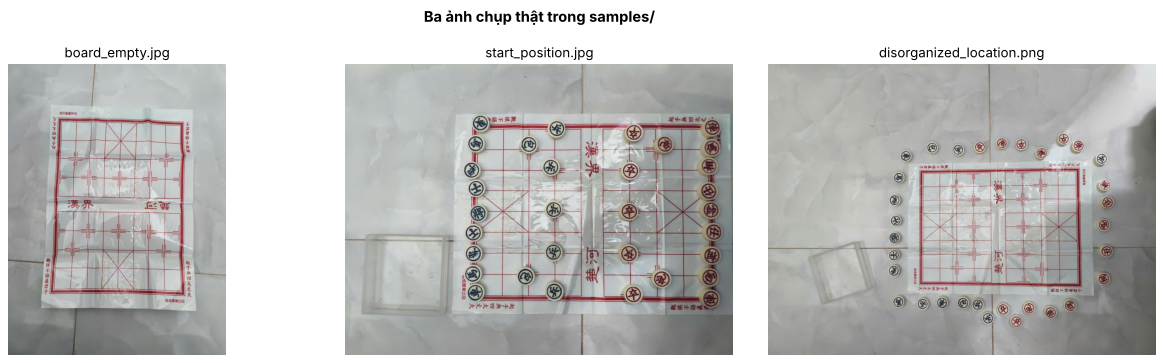

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for a, n in zip(axes, names):
    a.imshow(RGB(imgs[n])); a.set_title(n); a.axis('off')
plt.suptitle('Ba ảnh chụp thật trong samples/', fontweight='bold'); plt.tight_layout(); plt.show()
img = imgs['start_position.jpg']     # ảnh chính dùng cho các bước minh hoạ
HINT = (1280, 480)                   # gợi ý phía quân Đỏ (cạnh phải ảnh) cho ảnh này

---
# 2. Hai nhánh tiền xử lý

Mỗi ảnh đi qua **hai nhánh độc lập**, rồi gặp nhau ở bước gán quân vào giao điểm:
- **Nhánh nhận diện quân** chuẩn bị ảnh cho YOLO11n (Bước 2) — giống hệt khi huấn luyện và khi chạy thật.
- **Nhánh định vị bàn cờ** dùng xử lý ảnh cổ điển (OpenCV), không học máy, để tìm 90 giao điểm.

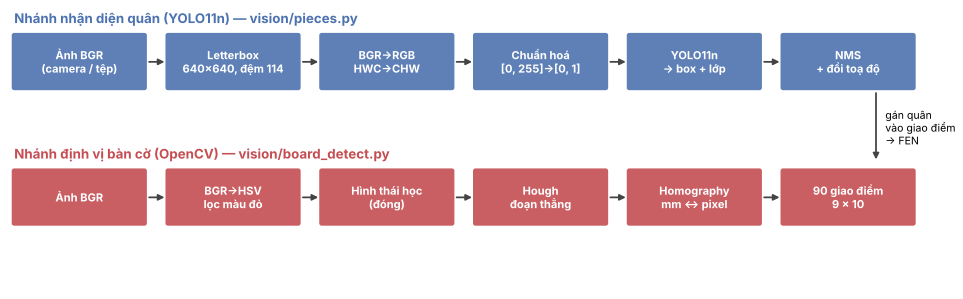

In [3]:
fig, ax = plt.subplots(figsize=(15, 4.6)); ax.axis('off'); ax.set_xlim(0, 15); ax.set_ylim(0, 4.6)
rows = [
    (3.3, '#4C72B0', 'Nhánh nhận diện quân (YOLO11n) — vision/pieces.py',
     ['Ảnh BGR\n(camera / tệp)', 'Letterbox\n640×640, đệm 114', 'BGR→RGB\nHWC→CHW', 'Chuẩn hoá\n[0, 255]→[0, 1]', 'YOLO11n\n→ box + lớp', 'NMS\n+ đổi toạ độ']),
    (1.1, '#C44E52', 'Nhánh định vị bàn cờ (OpenCV) — vision/board_detect.py',
     ['Ảnh BGR', 'BGR→HSV\nlọc màu đỏ', 'Hình thái học\n(đóng)', 'Hough\nđoạn thẳng', 'Homography\nmm ↔ pixel', '90 giao điểm\n9 × 10']),
]
for y, col, title, steps in rows:
    ax.text(0.1, y + 1.05, title, fontsize=12, fontweight='bold', color=col)
    for i, s in enumerate(steps):
        x = 0.1 + i * 2.48
        ax.add_patch(FancyBboxPatch((x, y), 2.1, 0.85, boxstyle='round,pad=0.04', fc=col, ec='none', alpha=0.9))
        ax.text(x + 1.05, y + 0.42, s, ha='center', va='center', color='white', fontsize=10, fontweight='bold')
        if i < len(steps) - 1:
            ax.annotate('', xy=(x + 2.46, y + 0.42), xytext=(x + 2.14, y + 0.42), arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#444'))
ax.annotate('', xy=(14.0, 2.1), xytext=(14.0, 3.25), arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#444'))
ax.text(14.15, 2.65, 'gán quân\nvào giao điểm\n→ FEN', fontsize=9.5, va='center')
plt.show()

---
# 3. Nhánh nhận diện quân: chuẩn bị ảnh cho YOLO11n

Trên Colab, Ultralytics tự làm các bước này. Trên robot (Python 3.6, không có Ultralytics) thư viện **tự cài đặt** chúng trong hàm `letterbox()` của `vision/pieces.py`:
1. **Letterbox**: thu ảnh về 640 × 640 **giữ tỉ lệ khung hình** (r = min(640/H, 640/W)), phần thiếu đệm xám 114 → quân tròn không bị méo.
2. **BGR → RGB**: OpenCV đọc ảnh theo BGR, mô hình học trên RGB.
3. **HWC → CHW + chiều batch**: tensor (1, 3, 640, 640).
4. **Chuẩn hoá**: chia 255 → giá trị trong [0, 1], kiểu float32.

In [4]:
print(inspect.getsource(letterbox))

def letterbox(img, size):
    h, w = img.shape[:2]
    r = min(size / float(h), size / float(w))
    nw, nh = int(round(w * r)), int(round(h * r))
    px, py = (size - nw) // 2, (size - nh) // 2
    canvas = np.full((size, size, 3), 114, np.uint8)
    canvas[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    blob = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB).astype(np.float32).transpose(2, 0, 1)[None] / 255.0
    return np.ascontiguousarray(blob), r, px, py



tensor (1, 3, 640, 640) float32 | min 0.031 max 1.000
tỉ lệ r = 0.500, đệm ngang 0 px, đệm dọc 80 px


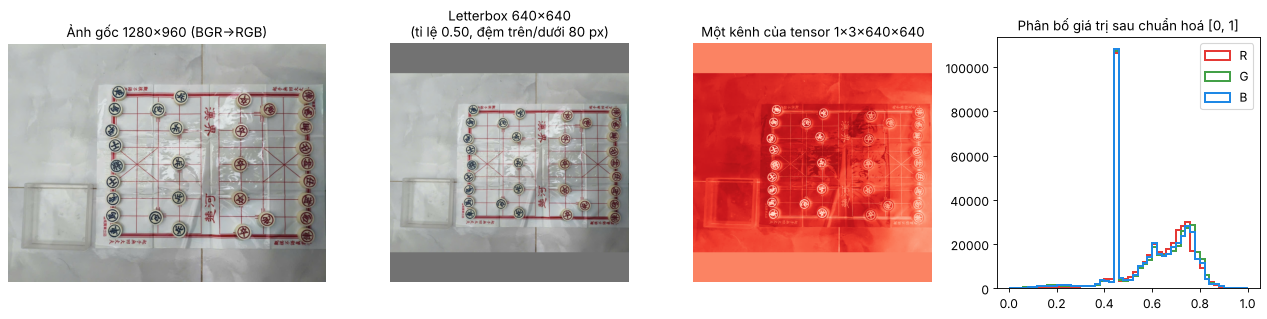

In [5]:
blob, r, px, py = letterbox(img, 640)
print('tensor', blob.shape, blob.dtype, '| min %.3f max %.3f' % (blob.min(), blob.max()))
print('tỉ lệ r = %.3f, đệm ngang %d px, đệm dọc %d px' % (r, px, py))
lb = (blob[0].transpose(1, 2, 0) * 255).astype(np.uint8)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), gridspec_kw={'width_ratios': [1.33, 1, 1, 1.1]})
axes[0].imshow(RGB(img)); axes[0].set_title('Ảnh gốc %d×%d (BGR→RGB)' % (img.shape[1], img.shape[0])); axes[0].axis('off')
axes[1].imshow(lb); axes[1].set_title('Letterbox 640×640\n(tỉ lệ %.2f, đệm trên/dưới %d px)' % (r, py)); axes[1].axis('off')
axes[2].imshow(blob[0, 0], cmap='Reds'); axes[2].set_title('Một kênh của tensor 1×3×640×640'); axes[2].axis('off')
for i, (ch, col) in enumerate(zip('RGB', ['#e53935', '#43a047', '#1e88e5'])):
    axes[3].hist(blob[0, i].ravel(), bins=50, range=(0, 1), histtype='step', color=col, lw=1.8, label=ch)
axes[3].set_title('Phân bố giá trị sau chuẩn hoá [0, 1]'); axes[3].legend()
plt.tight_layout(); plt.show()

**Đổi toạ độ ngược** (sau khi YOLO trả hộp trên ảnh 640): x = (x′ − pad_x) / r, y = (y′ − pad_y) / r. Kiểm tra: lấy 4 góc ảnh gốc → letterbox → đổi ngược phải ra đúng toạ độ cũ.

In [6]:
h, w = img.shape[:2]
corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], float)
fwd = corners * r + [px, py]            # toạ độ trên ảnh 640×640
back = (fwd - [px, py]) / r             # đổi ngược
print('trên ảnh 640:', fwd.round(1).tolist())
print('sai lệch đổi ngược lớn nhất: %.2e px' % np.abs(back - corners).max())

trên ảnh 640: [[0.0, 80.0], [640.0, 80.0], [640.0, 560.0], [0.0, 560.0]]
sai lệch đổi ngược lớn nhất: 0.00e+00 px


> Các bước còn lại của nhánh này nằm ở **Bước 2 (`train_yolo11.ipynb`)**: chọn `imgsz = 640` từ phân bố kích thước quân, và **tăng cường dữ liệu** (xoay ±180°, đổi màu HSV, mosaic, **không lật** vì lật biến chữ Hán thành ảnh gương).

---
# 4. Nhánh định vị bàn cờ (`vision/board_detect.py`)

Bàn cờ của đề tài có đường kẻ **màu đỏ** trên nền trắng. Thư viện tìm 90 giao điểm **không cần marker** qua 5 bước dưới đây.

## 4.1. Chuyển sang không gian màu HSV
Ở RGB, "màu đỏ" phụ thuộc mạnh vào độ sáng. HSV tách **sắc độ H** khỏi **độ bão hoà S** và **độ sáng V**: đường kẻ đỏ và chữ quân Đỏ có H gần 0; nền trắng, mặt quân màu kem có S thấp.

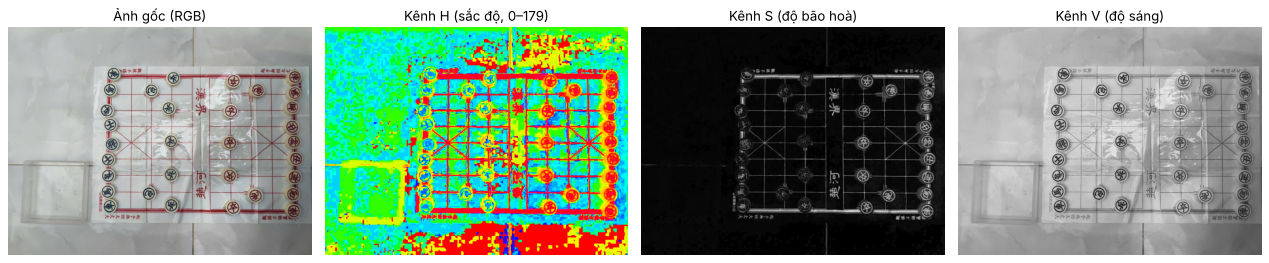

In [7]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(RGB(img)); axes[0].set_title('Ảnh gốc (RGB)')
for ax, k, t, cm in zip(axes[1:], range(3), ['Kênh H (sắc độ, 0–179)', 'Kênh S (độ bão hoà)', 'Kênh V (độ sáng)'], ['hsv', 'gray', 'gray']):
    ax.imshow(hsv[..., k], cmap=cm); ax.set_title(t)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 4.2. Phân ngưỡng màu đỏ
Thang H của OpenCV là 0–179 và **khép vòng**: màu đỏ nằm ở **cả hai đầu**. Vì vậy mặt nạ đỏ là hợp của hai khoảng (hàm `red_mask()`):

`mask = inRange(HSV, (0,70,60), (10,255,255))  OR  inRange(HSV, (165,70,60), (180,255,255))`

def red_mask(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    m1 = cv2.inRange(hsv, (0, 70, 60), (10, 255, 255))
    m2 = cv2.inRange(hsv, (165, 70, 60), (180, 255, 255))
    return cv2.bitwise_or(m1, m2)



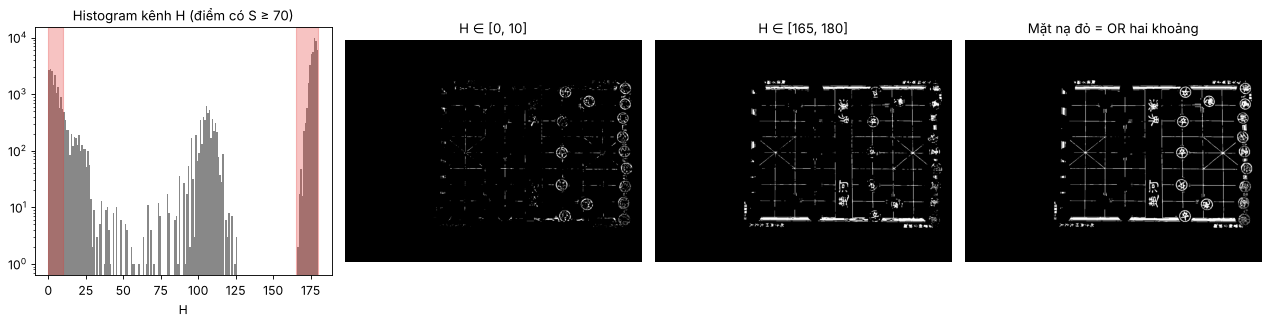

Tỉ lệ điểm ảnh đỏ: 4.4%


In [8]:
print(inspect.getsource(bd.red_mask))
m1 = cv2.inRange(hsv, (0, 70, 60), (10, 255, 255))
m2 = cv2.inRange(hsv, (165, 70, 60), (180, 255, 255))
mask = bd.red_mask(img)
fig = plt.figure(figsize=(16, 4.2))
ax = fig.add_subplot(1, 4, 1)
sat = hsv[..., 1] >= 70
ax.hist(hsv[..., 0][sat].ravel(), bins=180, range=(0, 180), color='#888')
ax.axvspan(0, 10, color='#e53935', alpha=0.3); ax.axvspan(165, 180, color='#e53935', alpha=0.3)
ax.set_title('Histogram kênh H (điểm có S ≥ 70)'); ax.set_xlabel('H'); ax.set_yscale('log')
for i, (mm, t) in enumerate([(m1, 'H ∈ [0, 10]'), (m2, 'H ∈ [165, 180]'), (mask, 'Mặt nạ đỏ = OR hai khoảng')]):
    a = fig.add_subplot(1, 4, i + 2); a.imshow(mm, cmap='gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()
print('Tỉ lệ điểm ảnh đỏ: %.1f%%' % (100 * (mask > 0).mean()))

## 4.3. Hình thái học: phép đóng và tìm vùng bàn cờ
Quân cờ che làm đường kẻ đứt đoạn. **Phép đóng** (giãn rồi co) với phần tử cấu trúc 5 × 5 lấp các khe nhỏ; đường viền ngoài lớn nhất cho biết vùng bàn cờ — đây là **phương án dự phòng** (hàm `_quad()`) khi dò đường thẳng thất bại.

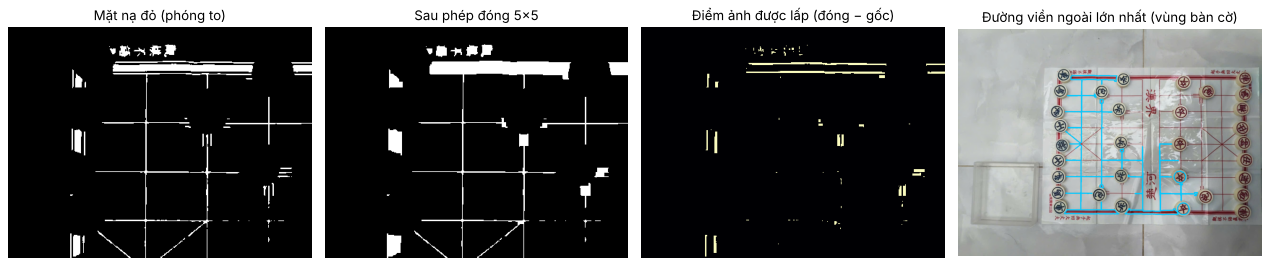

Số điểm ảnh được lấp: 16215


In [9]:
k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
res = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = res[0] if len(res) == 2 else res[1]
c = max(cnts, key=cv2.contourArea)
vis = RGB(img).copy(); cv2.drawContours(vis, [c], -1, (0, 200, 255), 3)
crop = (slice(150, 470), slice(330, 750))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
axes[0].imshow(mask[crop], cmap='gray'); axes[0].set_title('Mặt nạ đỏ (phóng to)')
axes[1].imshow(closed[crop], cmap='gray'); axes[1].set_title('Sau phép đóng 5×5')
axes[2].imshow(cv2.absdiff(closed, mask)[crop], cmap='magma'); axes[2].set_title('Điểm ảnh được lấp (đóng − gốc)')
axes[3].imshow(vis); axes[3].set_title('Đường viền ngoài lớn nhất (vùng bàn cờ)')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()
print('Số điểm ảnh được lấp: %d' % int((cv2.absdiff(closed, mask) > 0).sum()))

## 4.4. Biến đổi Hough: tìm hai họ đường lưới
`cv2.HoughLinesP` chạy trên mặt nạ đỏ (độ phân giải góc 0,5°, ngưỡng phiếu 4% và độ dài tối thiểu 5% cạnh ảnh). Histogram góc của các đoạn (trọng số = độ dài) có **hai đỉnh cách nhau ≈ 90°** = họ đường dọc và họ đường ngang (hàm `_line_families()`).

họ đường góc 90.0°: 144 đoạn
họ đường góc 179.0°: 117 đoạn


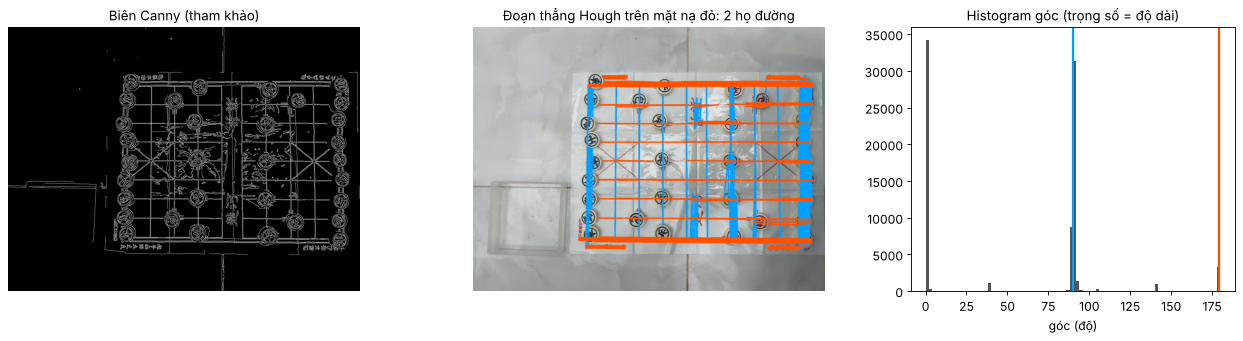

In [10]:
fams = bd._line_families(mask)
edges = cv2.Canny(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 60, 160)
vis = RGB(img).copy()
cols = [(0, 160, 255), (255, 80, 0)]
for (a, segs, ln), col in zip(fams, cols):
    for x1, y1, x2, y2 in segs.astype(int):
        cv2.line(vis, (x1, y1), (x2, y2), col, 3)
    print('họ đường góc %.1f°: %d đoạn' % (a, len(segs)))
L = max(img.shape[:2])
segs = cv2.HoughLinesP(mask, 1, np.pi / 360, threshold=int(0.04 * L), minLineLength=int(0.05 * L), maxLineGap=int(0.06 * L)).reshape(-1, 4)
d = segs[:, 2:] - segs[:, :2]
ang = np.degrees(np.arctan2(d[:, 1], d[:, 0])) % 180
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1, 1, 0.8]})
axes[0].imshow(edges, cmap='gray'); axes[0].set_title('Biên Canny (tham khảo)'); axes[0].axis('off')
axes[1].imshow(vis); axes[1].set_title('Đoạn thẳng Hough trên mặt nạ đỏ: 2 họ đường'); axes[1].axis('off')
axes[2].hist(ang, bins=90, range=(0, 180), weights=np.hypot(d[:, 0], d[:, 1]), color='#555')
for (a, _, _), col in zip(fams, cols):
    axes[2].axvline(a, color=np.array(col) / 255, lw=2)
axes[2].set_title('Histogram góc (trọng số = độ dài)'); axes[2].set_xlabel('góc (độ)')
plt.tight_layout(); plt.show()

## 4.5. Homography và 90 giao điểm
Các đường tìm được được so khớp với mẫu 9 cột × 10 hàng của bàn cờ thật (kích thước trong `config/board.yaml`), cho các cặp điểm **mm ↔ pixel**; homography H (3 × 3) được ước lượng bằng RANSAC. Sau đó thư viện nắn ảnh, dò lại từng đường theo đoạn ngắn và khớp đường cong bậc 2 (tấm bàn hơi cong), lặp 2 lần. Hàm chính: `locate()`.

Số đường lưới khớp được: 17 | sai lệch 90 điểm so với homography: 0.61 mm
H =
 [[ 8.4700000e-02 -2.5663000e+00  1.2073224e+03]
 [-2.4975000e+00  1.5800000e-02  7.6924890e+02]
 [ 1.0000000e-04  0.0000000e+00  1.0000000e+00]]


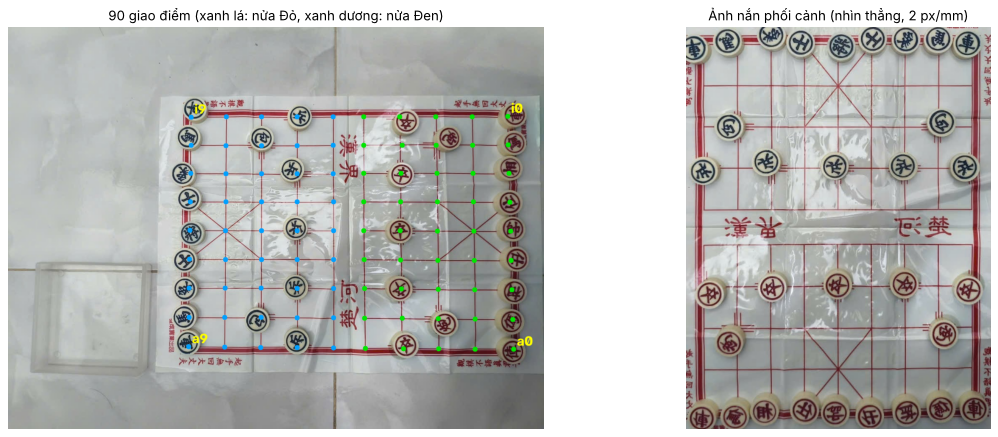

In [11]:
fix = bd.locate(img, g, red_hint=HINT)
print('Số đường lưới khớp được: %s | sai lệch 90 điểm so với homography: %.2f mm' % (fix.n_lines, fix.rms_mm))
print('H =\n', np.round(fix.H, 4))
S, m = 2.0, 15
W, Lh = int((g.width + 2 * m) * S), int((g.length + 2 * m) * S)
T = np.array([[1 / S, 0, -m], [0, 1 / S, -m], [0, 0, 1]])
warped = cv2.warpPerspective(img, fix.H.dot(T), (W, Lh), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR)
vis = RGB(img).copy()
for (f, rk), (x, y) in fix.pts_px.items():
    cv2.circle(vis, (int(x), int(y)), 6, (0, 230, 0) if rk < 5 else (0, 160, 255), -1)
for k2, t in [((0, 0), 'a0'), ((8, 0), 'i0'), ((0, 9), 'a9'), ((8, 9), 'i9')]:
    x, y = fix.pts_px[k2]
    cv2.putText(vis, t, (int(x) + 8, int(y) - 8), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 0), 3)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1.35, 1]})
axes[0].imshow(vis); axes[0].set_title('90 giao điểm (xanh lá: nửa Đỏ, xanh dương: nửa Đen)'); axes[0].axis('off')
axes[1].imshow(RGB(cv2.rotate(warped, cv2.ROTATE_180))); axes[1].set_title('Ảnh nắn phối cảnh (nhìn thẳng, 2 px/mm)'); axes[1].axis('off')
plt.tight_layout(); plt.show()

## 4.6. Gán quân vào giao điểm
Tâm mỗi quân (từ YOLO11n) được gán vào giao điểm gần nhất nếu cách nhỏ hơn **0,45 cỡ ô**; xa hơn thì coi là quân ngoài bàn (vùng chờ, quân bị ăn). Hai quân rơi vào cùng giao điểm → giữ quân tin cậy cao hơn.

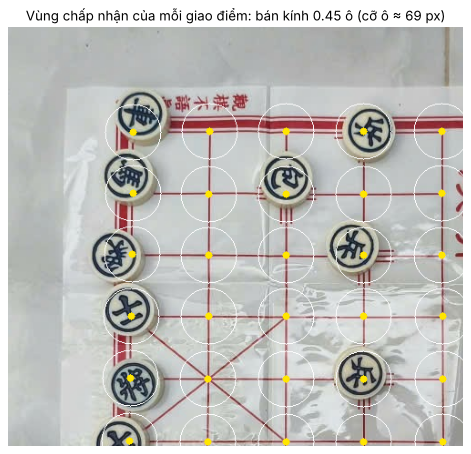

In [12]:
cell = np.median([np.linalg.norm(np.subtract(fix.pts_px[(f + 1, 0)], fix.pts_px[(f, 0)])) for f in range(8)])
vis = RGB(img).copy()
for (f, rk), (x, y) in fix.pts_px.items():
    cv2.circle(vis, (int(x), int(y)), int(0.45 * cell), (255, 255, 255), 1)
    cv2.circle(vis, (int(x), int(y)), 4, (255, 230, 0), -1)
fig, ax = plt.subplots(figsize=(9, 6.8))
ax.imshow(vis[100:560, 300:800]); ax.axis('off')
ax.set_title('Vùng chấp nhận của mỗi giao điểm: bán kính 0.45 ô (cỡ ô ≈ %.0f px)' % cell)
plt.show()

---
# 5. Định vị bàn cờ trên cả 3 ảnh mẫu
Cùng một hàm `locate()` chạy trên bàn trống, bàn có đủ 32 quân và bàn có quân để lộn xộn xung quanh. Quân che đường kẻ nhưng hai họ đường vẫn đủ để khớp lưới.

board_empty.jpg              đường khớp: 19   sai lệch: 1.44 mm


start_position.jpg           đường khớp: 18   sai lệch: 0.49 mm
disorganized_location.png    đường khớp: 16   sai lệch: 0.80 mm


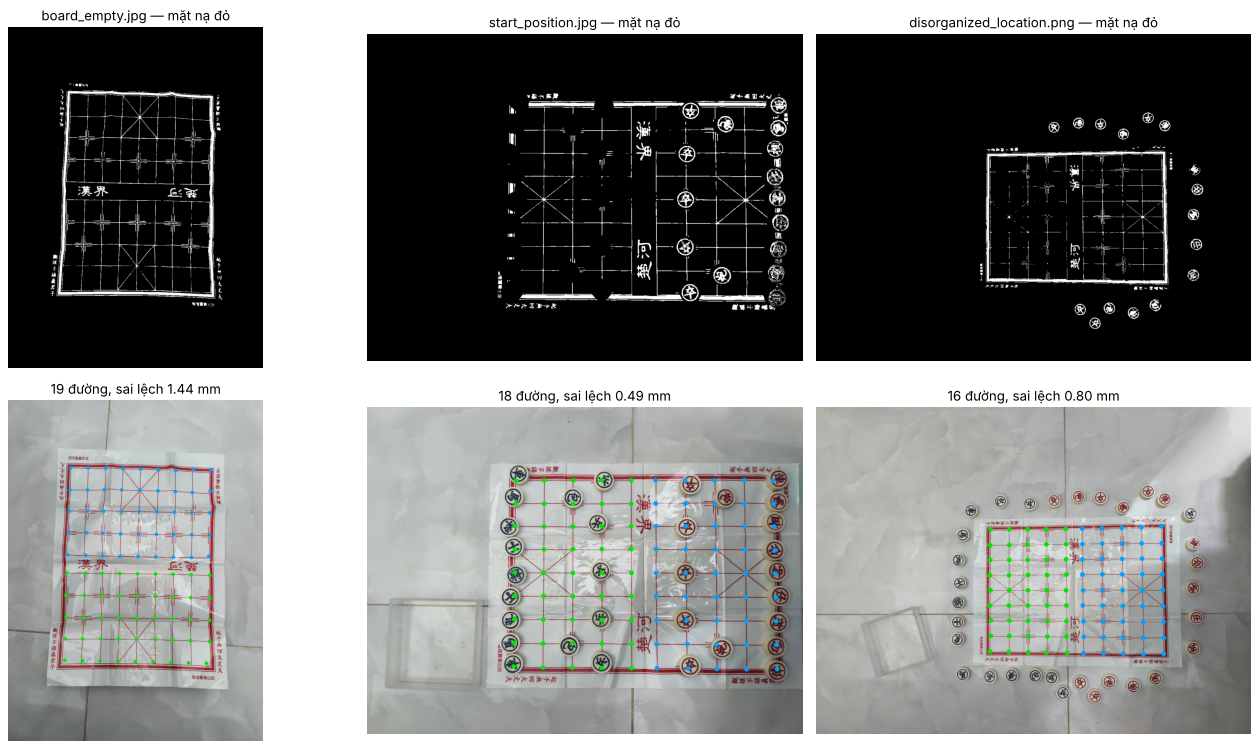

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for j, n in enumerate(names):
    im = imgs[n]
    fx = bd.locate(im, g)
    mk = bd.red_mask(im)
    vis = RGB(im).copy()
    for (f, rk), (x, y) in fx.pts_px.items():
        cv2.circle(vis, (int(x), int(y)), 7, (0, 230, 0) if rk < 5 else (0, 160, 255), -1)
    axes[0, j].imshow(mk, cmap='gray'); axes[0, j].set_title('%s — mặt nạ đỏ' % n)
    axes[1, j].imshow(vis); axes[1, j].set_title('%d đường, sai lệch %.2f mm' % (fx.n_lines, fx.rms_mm))
    print('%-28s đường khớp: %2d   sai lệch: %.2f mm' % (n, fx.n_lines, fx.rms_mm))
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

---
# 6. Xác định màu quân bằng phân ngưỡng HSV
Ngoài YOLO, thư viện kiểm tra **màu chữ** trên mặt quân bằng xử lý ảnh (hàm `ink_color()` trong `vision/pieces.py`): trong hình tròn bán kính 0,8r quanh tâm quân, đếm điểm **"mực đỏ"** (H ≤ 10 hoặc H ≥ 160, S ≥ 80, V ≥ 40) và điểm **"mực tối"** (mực xanh đậm H ∈ [70, 135] hoặc điểm rất tối). Không dùng "V thấp" đơn thuần vì mặt quân kem trong bóng râm cũng tối.

In [14]:
print(inspect.getsource(ink_color))

def ink_color(bgr, x, y, r):
    """Màu chữ trên mặt quân: đếm điểm ảnh ĐỎ và điểm ảnh MỰC TỐI (xanh đậm/đen) trong hình tròn 0.8r.
    Trả về ('red' | 'black' | None, độ tin 0..1, (số đỏ, số tối))."""
    h, w = bgr.shape[:2]
    rr = max(4, int(r * 0.8))
    x0, y0, x1, y1 = int(x - rr), int(y - rr), int(x + rr) + 1, int(y + rr) + 1
    if x0 < 0 or y0 < 0 or x1 > w or y1 > h:
        x0, y0, x1, y1 = max(0, x0), max(0, y0), min(w, x1), min(h, y1)
    crop = bgr[y0:y1, x0:x1]
    if crop.size == 0:
        return None, 0.0, (0, 0)
    yy, xx = np.mgrid[y0:y1, x0:x1]
    disk = (xx - x) ** 2 + (yy - y) ** 2 <= rr * rr
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    H, S, V = hsv[..., 0].astype(int), hsv[..., 1].astype(int), hsv[..., 2].astype(int)
    red = ((H <= 10) | (H >= 160)) & (S >= 80) & (V >= 40) & disk
    # mực quân Đen là xanh đậm (H 70..135). Không dùng "V thấp" vì mặt quân màu kem trong bóng râm cũng tối
    dark = (~red) & disk & (((H >= 70) & (H <= 135) & (S >= 40)

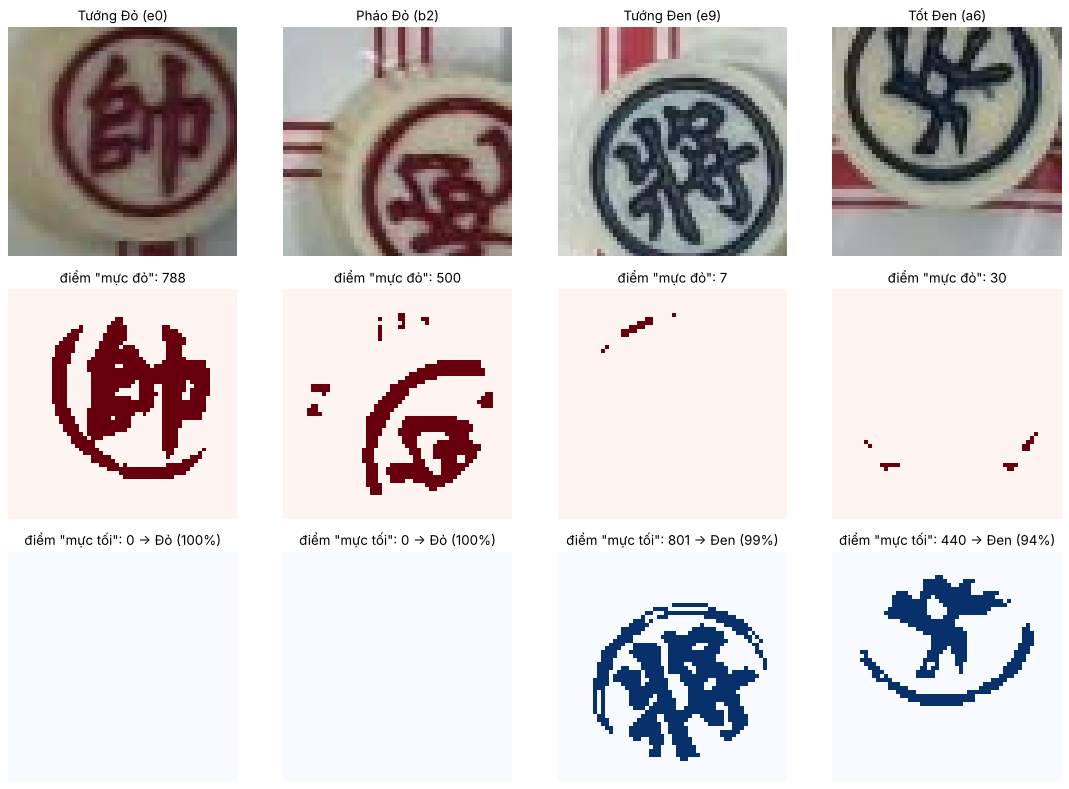

In [15]:
picks = [((4, 0), 'Tướng Đỏ (e0)'), ((1, 2), 'Pháo Đỏ (b2)'), ((4, 9), 'Tướng Đen (e9)'), ((0, 6), 'Tốt Đen (a6)')]
rr = int(cell * 0.42)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for j, (sq, t) in enumerate(picks):
    x, y = fix.pts_px[sq]
    x0, y0 = int(x - rr), int(y - rr)
    cropb = img[y0:y0 + 2 * rr, x0:x0 + 2 * rr]
    hs = cv2.cvtColor(cropb, cv2.COLOR_BGR2HSV).astype(int)
    H_, S_, V_ = hs[..., 0], hs[..., 1], hs[..., 2]
    yy, xx = np.mgrid[0:cropb.shape[0], 0:cropb.shape[1]]
    disk = (xx - rr) ** 2 + (yy - rr) ** 2 <= (0.8 * rr) ** 2
    red = ((H_ <= 10) | (H_ >= 160)) & (S_ >= 80) & (V_ >= 40) & disk
    dark = (~red) & disk & (((H_ >= 70) & (H_ <= 135) & (S_ >= 40) & (V_ < 170)) | ((V_ < 50) & (S_ < 80)))
    colr, conf, (nr, nd) = ink_color(img, x, y, rr)
    axes[0, j].imshow(RGB(cropb)); axes[0, j].set_title(t)
    axes[1, j].imshow(red, cmap='Reds'); axes[1, j].set_title('điểm "mực đỏ": %d' % nr)
    axes[2, j].imshow(dark, cmap='Blues'); axes[2, j].set_title('điểm "mực tối": %d → %s (%.0f%%)' % (nd, 'Đỏ' if colr == 'red' else 'Đen', conf * 100))
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

---
# 7. Tăng cường chất lượng ảnh (`vision/enhance.py`)

Thư viện có mô-đun tăng cường ảnh, cấu hình ở mục `brain.enhance` của `config/robot.yaml`. Bốn kỹ thuật, áp dụng theo thứ tự:

| Tình huống | Kỹ thuật | Hàm | Nguyên lý |
|---|---|---|---|
| Nhiễu (thiếu sáng, ISO cao) | Lọc song phương, d = 9, độ mạnh theo mức nhiễu | `denoise()` | Trọng số theo khoảng cách và độ chênh màu → khử nhiễu, giữ biên đường kẻ / nét chữ |
| Ám màu đèn vàng | Cân bằng trắng Gray-World | `gray_world()` | Nhân mỗi kênh để trung bình 3 kênh bằng nhau |
| Thiếu sáng toàn cục | Gamma (chỉ chế độ manual) | `gamma()` | I_out = 255·(I_in/255)^γ bằng bảng tra (LUT) |
| Thiếu sáng / ngược sáng | CLAHE trên kênh L (LAB), clipLimit 2,0, lưới 8 × 8 | `clahe()` | Cân bằng histogram cục bộ, giới hạn tương phản; không làm lệch màu đỏ/đen |

**Chế độ `auto` (mặc định):** đo ảnh trước bằng `measure()` rồi chỉ bật bước nào cần — ảnh tốt đi qua nguyên vẹn:
- **độ sáng** = trung bình kênh L của LAB → L < 100 thì bật CLAHE;
- **mức nhiễu** = độ lệch chuẩn nhiễu theo phương pháp Immerkær (tích chập mặt nạ Laplace kép) → > 4 thì bật lọc song phương;
- **độ ám màu** = trung bình kênh lớn nhất / nhỏ nhất → > 1,25 thì bật Gray-World.

Mặc định chỉ áp dụng cho **ảnh dùng để định vị bàn cờ** (`apply_to: [board]`); ảnh đưa vào YOLO giữ nguyên vì mô hình đã học với tăng cường HSV mạnh (hsv_v 0,4; hsv_s 0,7) và chưa có ảnh xấu thật từ camera robot để đo.

> Ảnh tối / ám màu / nhiễu dưới đây được **mô phỏng** từ `start_position.jpg`.

In [16]:
from vision import enhance as E
print(inspect.getsource(E.plan))

def plan(stats, cfg=None):
    """Danh sách bước sẽ áp dụng cho ảnh có số đo stats, theo cấu hình cfg."""
    s = settings(cfg)
    mode = s['mode']
    if mode == 'off':
        return []
    steps = []
    if mode == 'manual':
        if s['denoise']:
            steps.append('denoise')
        if s['white_balance']:
            steps.append('white_balance')
        if s['gamma']:
            steps.append('gamma')
        if s['clahe']:
            steps.append('clahe')
        return steps
    # auto
    if s['denoise'] and stats['noise'] > s['noise_max']:
        steps.append('denoise')
    if s['white_balance'] and stats['cast'] > s['cast_max']:
        steps.append('white_balance')
    if s['clahe'] and stats['brightness'] < s['dark_L']:
        steps.append('clahe')
    return steps



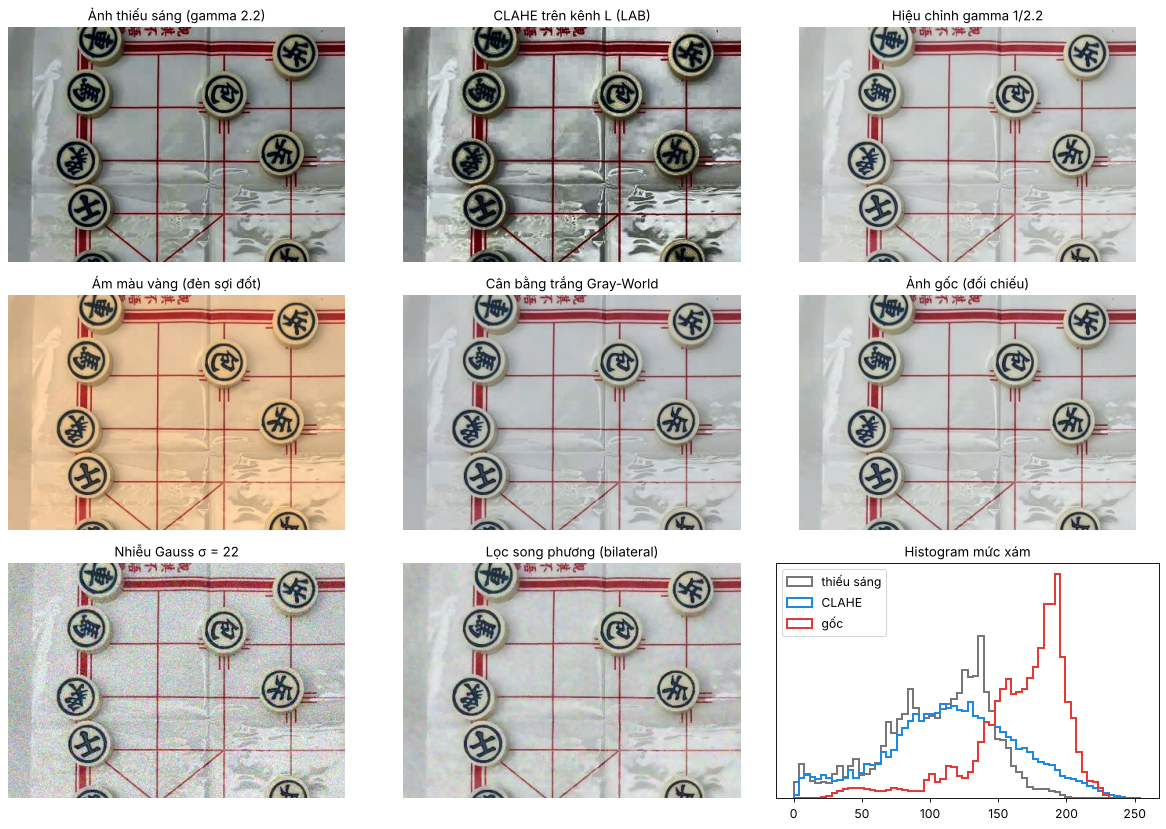

In [17]:
dark_img = E.gamma(img, 2.2)                                                 # mô phỏng thiếu sáng
clahe_img = E.clahe(dark_img)
gam_img = E.gamma(dark_img, 1 / 2.2)
warm = np.clip(img.astype(np.float32) * np.array([0.75, 0.95, 1.15]), 0, 255).astype(np.uint8)   # mô phỏng ám vàng
gw = E.gray_world(warm)
noisy = np.clip(img.astype(np.int16) + np.random.RandomState(0).normal(0, 22, img.shape).astype(np.int16), 0, 255).astype(np.uint8)
den = E.denoise(noisy, E.measure(noisy)['noise'])

crop2 = (slice(180, 480), slice(330, 760))
pairs = [(dark_img, 'Ảnh thiếu sáng (gamma 2.2)'), (clahe_img, 'CLAHE trên kênh L (LAB)'), (gam_img, 'Hiệu chỉnh gamma 1/2.2'),
         (warm, 'Ám màu vàng (đèn sợi đốt)'), (gw, 'Cân bằng trắng Gray-World'), (img, 'Ảnh gốc (đối chiếu)'),
         (noisy, 'Nhiễu Gauss σ = 22'), (den, 'Lọc song phương (bilateral)'), (None, None)]
fig, axes = plt.subplots(3, 3, figsize=(15, 10.5))
for a, (im_, t) in zip(axes.ravel(), pairs):
    a.axis('off')
    if im_ is None:
        for im2, t2, col in [(dark_img, 'thiếu sáng', '#777'), (clahe_img, 'CLAHE', '#1e88e5'), (img, 'gốc', '#e53935')]:
            a.hist(cv2.cvtColor(im2, cv2.COLOR_BGR2GRAY).ravel(), bins=64, range=(0, 255), histtype='step', lw=1.8, color=col, label=t2)
        a.axis('on'); a.set_title('Histogram mức xám'); a.legend(); a.set_yticks([])
        continue
    a.imshow(RGB(im_[crop2])); a.set_title(t)
plt.tight_layout(); plt.show()

## 7.1. Chế độ `auto` quyết định gì, và có giúp định vị bàn cờ không?
Mỗi ảnh: đo độ sáng / nhiễu / ám màu → `auto` chọn các bước → so sánh định vị bàn cờ **trước** và **sau** tăng cường.

In [18]:
import time
def loc(b):
    f = bd.locate(b, g, red_hint=HINT)
    return 'MẤT BÀN' if f is None else '%d đường, %.2f mm' % (f.n_lines, f.rms_mm)

def add_noise(b, s, seed=0):
    return np.clip(b.astype(np.int16) + np.random.RandomState(seed).normal(0, s, b.shape).astype(np.int16), 0, 255).astype(np.uint8)

cases = [('gốc', img), ('bàn trống', imgs['board_empty.jpg']), ('quân lộn xộn', imgs['disorganized_location.png']),
         ('tối (gamma 2.2)', E.gamma(img, 2.2)), ('rất tối (gamma 3)', E.gamma(img, 3.0)), ('cực tối (gamma 4)', E.gamma(img, 4.0)),
         ('ám vàng', warm), ('ám vàng mạnh', np.clip(img.astype(np.float32) * np.array([0.55, 0.9, 1.25]), 0, 255).astype(np.uint8)),
         ('nhiễu σ=8', add_noise(img, 8)), ('nhiễu σ=16', add_noise(img, 16)), ('nhiễu σ=22', add_noise(img, 22)),
         ('nhiễu σ=30', add_noise(img, 30)), ('nhiễu σ=40', add_noise(img, 40)), ('rất tối + nhiễu σ=16', add_noise(E.gamma(img, 3.0), 16, 1))]
rows = []
print('%-22s %5s %6s %5s | %-22s | %-16s | %s' % ('ảnh', 'L', 'nhiễu', 'ám', 'auto áp dụng', 'trước', 'sau'))
for t, im_ in cases:
    t0 = time.time(); out, info = E.enhance(im_, {'mode': 'auto'}); dt = (time.time() - t0) * 1000
    st = info['stats']
    before = loc(im_); after = loc(out) if info['steps'] else '(giữ nguyên)'
    rows.append((t, st, info['steps'], before, after))
    print('%-22s %5.0f %6.1f %5.2f | %-22s | %-16s | %s   (%.0f ms)' % (t, st['brightness'], st['noise'], st['cast'],
          ', '.join(info['steps']) or '-', before, after, dt))

ảnh                        L  nhiễu    ám | auto áp dụng           | trước            | sau


gốc                      173    0.8  1.02 | -                      | 17 đường, 0.61 mm | (giữ nguyên)   (31 ms)


bàn trống                175    0.5  1.01 | -                      | 19 đường, 1.47 mm | (giữ nguyên)   (33 ms)
quân lộn xộn             174    0.7  1.02 | -                      | 16 đường, 0.73 mm | (giữ nguyên)   (31 ms)


tối (gamma 2.2)          112    0.9  1.03 | -                      | 15 đường, 0.65 mm | (giữ nguyên)   (30 ms)


rất tối (gamma 3)         85    0.9  1.04 | clahe                  | 16 đường, 0.92 mm | 14 đường, 0.82 mm   (43 ms)


cực tối (gamma 4)         60    0.8  1.05 | clahe                  | 12 đường, 0.54 mm | 13 đường, 0.76 mm   (48 ms)


... (4 outputs left out)

nhiễu σ=22               174   14.5  1.02 | denoise                | MẤT BÀN          | 16 đường, 0.69 mm   (98 ms)


nhiễu σ=30               174   19.6  1.02 | denoise                | MẤT BÀN          | 15 đường, 0.79 mm   (114 ms)


nhiễu σ=40               175   25.6  1.02 | denoise                | MẤT BÀN          | 10 đường, 0.67 mm   (101 ms)


rất tối + nhiễu σ=16      86   10.4  1.04 | denoise, clahe         | MẤT BÀN          | MẤT BÀN   (115 ms)


**Nhận xét:**
- **Ảnh tốt** (cả 3 ảnh mẫu) và ảnh hơi tối: `auto` **không làm gì** → kết quả giữ nguyên như trước khi có mô-đun này.
- **Thiếu sáng, ám màu:** định vị bàn cờ vẫn chạy được ngay cả khi chưa tăng cường (phân ngưỡng trên HSV ít phụ thuộc độ sáng); CLAHE / Gray-World đưa ảnh về gần ảnh tốt, kết quả tương đương.
- **Nhiễu mạnh (σ ≥ 22):** không tăng cường thì **mất bàn cờ**; sau lọc song phương **tìm lại được** tới σ = 40. Đây là trường hợp tăng cường có tác dụng rõ.
- **Giới hạn:** ảnh vừa rất tối vừa nhiễu vẫn mất bàn sau tăng cường — khi đó thư viện chuyển sang khớp lưới từ tâm quân (`lattice`) hoặc báo chụp lại.
- Thời gian tăng cường ~ 30–140 ms / ảnh 1280 × 960 trên CPU Colab; bật cho ảnh YOLO (`apply_to: [board, pieces]`) cần đo thêm trên ảnh thật từ camera robot.

---
# 8. Đối chiếu với báo cáo

| Mục notebook | Hình trong báo cáo (Chương 4) |
|---|---|
| 2. Hai nhánh tiền xử lý | Hình 4.1 |
| 3. Letterbox, chuẩn hoá | Hình 4.11 |
| 4.1 HSV | Hình 4.15 |
| 4.2 Phân ngưỡng đỏ | Hình 4.16 |
| 4.3 Hình thái học | Hình 4.17 |
| 4.4 Hough | Hình 4.18 |
| 4.5 Homography, 90 giao điểm | Hình 4.19 |
| 4.6 Gán quân vào giao điểm | Hình 4.20 |
| 6. Màu quân | Hình 4.21 |
| 7. Tăng cường chất lượng ảnh | Hình 4.22, Bảng 4.6 |

Các hình 4.2–4.10 lấy từ **Bước 1** (`build_dataset.ipynb`), hình 4.12–4.14 từ **Bước 2** (`train_yolo11.ipynb`).